# Phase 5 — Country Clustering

This phase uses `country_profile.csv` generated by Phase 2. It scales the country-level
profile features, selects a KMeans cluster count using silhouette score, saves the
clustering bundle and the exact CSV artifacts expected by `app.py`.

Run Phase 2 first. No synthetic observations are created.


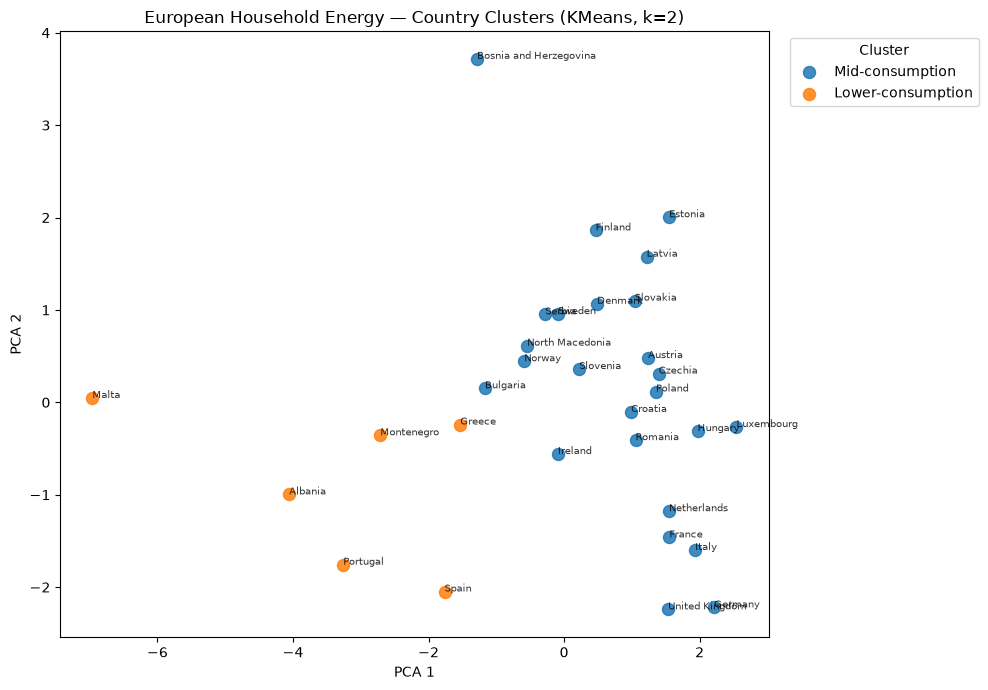

Phase 5 completed.
Countries: 31 | Features: 11 | Selected k: 2
Saved: C:\Users\LOQ\Downloads\European_Household_Energy_Project\European_Household_Energy_Project\models\clustering_bundle.joblib
Saved: C:\Users\LOQ\Downloads\European_Household_Energy_Project\European_Household_Energy_Project\outputs\evaluation_reports\phase5_clusters.csv
Saved: C:\Users\LOQ\Downloads\European_Household_Energy_Project\European_Household_Energy_Project\outputs\evaluation_reports\phase5_cluster_profile.csv


In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

CWD = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [CWD, *CWD.parents] if (p / "app.py").exists()), CWD)
PROCESSED_CANDIDATES = [
    PROJECT_ROOT.parent / "data" / "processed",
    PROJECT_ROOT / "data" / "processed",
    PROJECT_ROOT / "notebooks" / "data" / "processed",
]
PROCESSED = next((p for p in PROCESSED_CANDIDATES if p.exists()), PROCESSED_CANDIDATES[0])

MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "outputs" / "evaluation_reports"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
for folder in [MODELS_DIR, REPORTS_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

PROFILE_PATH = PROCESSED / "country_profile.csv"
if not PROFILE_PATH.exists():
    # Search the notebook directory and all parent directories for the profile.
    PROFILE_PATH = next(
        (
            base / "data" / "processed" / "country_profile.csv"
            for base in [CWD, *CWD.parents]
            if (base / "data" / "processed" / "country_profile.csv").exists()
        ),
        PROFILE_PATH,
    )

    if not PROFILE_PATH.exists():
        raise FileNotFoundError(
            f"{PROFILE_PATH} not found. Run Phase_2_fixed_paths.ipynb from start to finish first."
        )

profile = pd.read_csv(PROFILE_PATH)
if "country" not in profile.columns:
    raise ValueError("country_profile.csv must contain a 'country' column.")

FEATURES = [
    "avg_total_tj", "cv_total", "growth_pct",
    "elec_share", "gas_share", "heat_share",
    "sh_share", "wh_share", "ck_share", "le_share", "sc_share",
]
FEATURES = [c for c in FEATURES if c in profile.columns]
if len(FEATURES) < 3:
    raise ValueError(f"Not enough expected profile features. Found: {FEATURES}")

work = profile[["country"] + FEATURES].copy()
for c in FEATURES:
    work[c] = pd.to_numeric(work[c], errors="coerce")
work = work.replace([np.inf, -np.inf], np.nan)
work = work.dropna(subset=FEATURES, how="all").reset_index(drop=True)

if len(work) < 3:
    raise ValueError(f"Need at least 3 eligible countries for clustering; found {len(work)}.")

X = work[FEATURES]
imputer = SimpleImputer(strategy="median")
X_imp = imputer.fit_transform(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imp)

# Evaluate feasible k values; silhouette is defined only for 2..n-1 clusters.
candidate_ks = range(2, min(7, len(work)))
scores = []
for k in candidate_ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_scaled)
    if len(np.unique(labels)) > 1:
        scores.append((k, silhouette_score(X_scaled, labels)))

if not scores:
    raise ValueError("Could not calculate a valid silhouette score for this country sample.")

best_k = max(scores, key=lambda x: x[1])[0]
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
labels = kmeans.fit_predict(X_scaled)

# Human-readable labels ordered by cluster average energy scale.
cluster_means = pd.DataFrame({"cluster_kmeans": labels, "avg_total_tj": work["avg_total_tj"]})
ordered_clusters = cluster_means.groupby("cluster_kmeans")["avg_total_tj"].mean().sort_values().index.tolist()
label_names = ["Lower-consumption", "Mid-consumption", "Higher-consumption", "Largest-consumption",
               "Cluster group 5", "Cluster group 6"]
label_map = {cluster_id: label_names[i] if i < len(label_names) else f"Cluster group {i+1}"
             for i, cluster_id in enumerate(ordered_clusters)}

clusters = work.copy()
clusters["cluster_kmeans"] = labels
clusters["cluster_label"] = clusters["cluster_kmeans"].map(label_map)

# Keep app.py's expected fields present, even if a source profile column is absent.
for col in ["avg_total_tj", "cv_total", "growth_pct", "elec_share", "gas_share",
            "heat_share", "sh_share", "wh_share", "ck_share", "le_share", "sc_share"]:
    if col not in clusters.columns:
        clusters[col] = np.nan

cluster_profile = (
    clusters.groupby(["cluster_kmeans", "cluster_label"], as_index=False)
    .agg(
        countries=("country", "count"),
        avg_total_tj=("avg_total_tj", "mean"),
        cv_total=("cv_total", "mean"),
        growth_pct=("growth_pct", "mean"),
        elec_share=("elec_share", "mean"),
        gas_share=("gas_share", "mean"),
        heat_share=("heat_share", "mean"),
        sh_share=("sh_share", "mean"),
        wh_share=("wh_share", "mean"),
        ck_share=("ck_share", "mean"),
        le_share=("le_share", "mean"),
        sc_share=("sc_share", "mean"),
    )
)

# PCA visualization; save coordinates too for auditability.
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
clusters["pca_1"] = coords[:, 0]
clusters["pca_2"] = coords[:, 1]

bundle = {
    "model": kmeans,
    "imputer": imputer,
    "scaler": scaler,
    "features": FEATURES,
    "k": int(best_k),
    "label_map": label_map,
}
joblib.dump(bundle, MODELS_DIR / "clustering_bundle.joblib")
clusters.to_csv(REPORTS_DIR / "phase5_clusters.csv", index=False)
cluster_profile.to_csv(REPORTS_DIR / "phase5_cluster_profile.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 7))
for cluster_id, group in clusters.groupby("cluster_kmeans"):
    ax.scatter(group["pca_1"], group["pca_2"], label=label_map[cluster_id], s=75, alpha=0.85)
    for _, row in group.iterrows():
        ax.annotate(row["country"], (row["pca_1"], row["pca_2"]), fontsize=7, alpha=0.8)
ax.set_title(f"European Household Energy — Country Clusters (KMeans, k={best_k})")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "phase5_pca_clusters.png", dpi=180, bbox_inches="tight")
plt.show()

print("Phase 5 completed.")
print("Countries:", len(clusters), "| Features:", len(FEATURES), "| Selected k:", best_k)
print("Saved:", MODELS_DIR / "clustering_bundle.joblib")
print("Saved:", REPORTS_DIR / "phase5_clusters.csv")
print("Saved:", REPORTS_DIR / "phase5_cluster_profile.csv")


## Outputs

- `models/clustering_bundle.joblib`
- `outputs/evaluation_reports/phase5_clusters.csv`
- `outputs/evaluation_reports/phase5_cluster_profile.csv`
- `outputs/figures/phase5_pca_clusters.png`

The outputs are generated from the actual Phase 2 country profile, not fabricated data.
